# Lab 10: Introduction to Machine Translation (MT)

**Student Name:** Abdullah Alnuwaysir 
**Student ID:** 2240005501

## Task 1: Understanding the Model Layers

### 1. What does the **Embedding** layer do to a word index?
The Embedding layer converts each word index (an integer) into a dense vector of fixed size (here 64 values). These vectors are learned during training, so words with similar meanings end up with similar vectors. It is more compact and more meaningful than one-hot encoding.

### 2. What is the role of the **Encoder LSTM**?
The Encoder LSTM reads the English sentence word by word and compresses the whole sentence into a single fixed-size vector (its final hidden state), called the **context vector**. This vector holds the meaning of the source sentence.

### 3. What does the **Decoder LSTM** do?
The Decoder LSTM takes the context vector (repeated for every output time step by `RepeatVector`) and generates the output sequence step by step. It produces one hidden state per French word position, which is then passed to the Dense layer to choose the actual words.

### 4. Why do we use `softmax` in the final layer?
At each time step the model must choose one word from the entire French vocabulary (a multi-class classification problem). Softmax converts the raw scores into probabilities that sum to 1, so we can pick the most likely word with `argmax`. It also works naturally with the `sparse_categorical_crossentropy` loss.

In [3]:
import re
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# Path to the dataset downloaded from Kaggle (change to your file name)
DATA_PATH = "eng_-french.csv"

df = pd.read_csv(DATA_PATH)
df = df.iloc[:, :2]               # Keep only the first two columns (English, French)
df.columns = ["english", "french"]  # Rename columns for easier access
print(df.shape)
df.head()

(175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [4]:
def clean(text):
    text = str(text).lower().strip()           # Lowercase and remove extra spaces
    text = re.sub(r"([?.!,])", r" \1 ", text)  # Separate punctuation from words
    text = re.sub(r"\s+", " ", text)           # Collapse multiple spaces into one
    return text.strip()

df = df.dropna().drop_duplicates()             # Remove missing values and duplicates
df["english"] = df["english"].apply(clean)
df["french"]  = df["french"].apply(clean)

# Keep only short sentences to make training faster
MAX_LEN = 8
df = df[(df["english"].str.split().str.len() <= MAX_LEN) &
        (df["french"].str.split().str.len()  <= MAX_LEN)]

# Take a random sample to keep the model light
df = df.sample(n=min(15000, len(df)), random_state=42).reset_index(drop=True)

english_sentences = df["english"].tolist()
french_sentences  = df["french"].tolist()
print(len(english_sentences), "sentence pairs")
print(english_sentences[:3], french_sentences[:3])

15000 sentence pairs
['you all passed the test .', "you can't make everybody happy .", 'this drives me nuts .'] ['vous avez tous passé le test .', 'on ne peut satisfaire tout le monde .', 'ça me rend dingue .']


In [5]:
# Tokenize English: assign an integer ID to each unique word
tokenizer_eng = Tokenizer(filters="")
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)
eng_word_index = tokenizer_eng.word_index

# Tokenize French in the same way
tokenizer_frn = Tokenizer(filters="")
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)
frn_word_index = tokenizer_frn.word_index

# Pad all sequences to the same length (zeros added at the end)
eng_padded = pad_sequences(eng_sequences, maxlen=MAX_LEN + 2, padding="post")
frn_padded = pad_sequences(frn_sequences, maxlen=MAX_LEN + 2, padding="post")

print("English vocab:", len(eng_word_index), " French vocab:", len(frn_word_index))
print("eng_padded shape:", eng_padded.shape, " frn_padded shape:", frn_padded.shape)

English vocab: 5073  French vocab: 8505
eng_padded shape: (15000, 10)  frn_padded shape: (15000, 10)


In [6]:
# Split data: 80% training, 20% testing
eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.2, random_state=42)

model = tf.keras.Sequential([
    # Convert word indices into dense vectors (mask_zero ignores the padding)
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=128, mask_zero=True),

    # Encoder: compress the English sentence into one context vector
    tf.keras.layers.LSTM(128),

    # Repeat the context vector once for every French output position
    tf.keras.layers.RepeatVector(frn_padded.shape[1]),

    # Decoder: generate a hidden state for each French word position
    tf.keras.layers.LSTM(128, return_sequences=True),

    # Output layer: probability of each French word at every time step
    tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(len(frn_word_index) + 1, activation="softmax"))
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ ?                      │   0 (unbuilt) │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Train the model (targets need an extra dimension for sparse categorical loss)
history = model.fit(eng_train, np.expand_dims(frn_train, -1),
                    epochs=20, batch_size=64, validation_split=0.1)

# Evaluate on the unseen test set
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f"Test Accuracy: {accuracy:.4f}")

Epoch 1/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 25s 129ms/step - accuracy: 0.3988 - loss: 4.9297 - val_accuracy: 0.3949 - val_loss: 4.2575
Epoch 2/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 23s 135ms/step - accuracy: 0.4073 - loss: 3.9743 - val_accuracy: 0.4112 - val_loss: 4.0188
Epoch 3/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 22s 131ms/step - accuracy: 0.4230 - loss: 3.7530 - val_accuracy: 0.4252 - val_loss: 3.8569
Epoch 4/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 23s 134ms/step - accuracy: 0.4496 - loss: 3.6110 - val_accuracy: 0.4459 - val_loss: 3.7824
Epoch 5/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 23s 135ms/step - accuracy: 0.4648 - loss: 3.5310 - val_accuracy: 0.4518 - val_loss: 3.7494
Epoch 6/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 23s 139ms/step - accuracy: 0.4746 - loss: 3.4668 - val_accuracy: 0.4610 - val_loss: 3.7189
Epoch 7/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 22s 133ms/step - accuracy: 0.4822 - loss: 3.4118 - val_accuracy: 0.4598 - val_loss: 3.6954
Epoch 8/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 21s 127ms/step - accuracy: 0.4881 - loss: 3

In [8]:
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sentence = clean(sentence)                                   # Apply the same cleaning
    seq = eng_tokenizer.texts_to_sequences([sentence])           # Words -> indices
    padded = pad_sequences(seq, maxlen=eng_padded.shape[1], padding="post")
    pred = model.predict(padded, verbose=0)                      # Probabilities per time step
    ids = np.argmax(pred, axis=-1)[0]                            # Most likely word ID at each step
    words = [frn_tokenizer.index_word[i] for i in ids if i != 0] # Indices -> words (skip padding)
    return " ".join(words)

# Test with common e-commerce sentences
tests = ["I love this product.", "How much is it?", "Where is my order?",
         "This is very good.", "I want to buy this."]

for s in tests:
    print(f"EN: {s}\nFR: {translate_sentence(s, model, tokenizer_eng, tokenizer_frn)}\n")

EN: I love this product.
FR: je êtes . .

EN: How much is it?
FR: est-ce ? ?

EN: Where is my order?
FR: est-ce est ? ?

EN: This is very good.
FR: c'est est est .

EN: I want to buy this.
FR: je ne pas . .



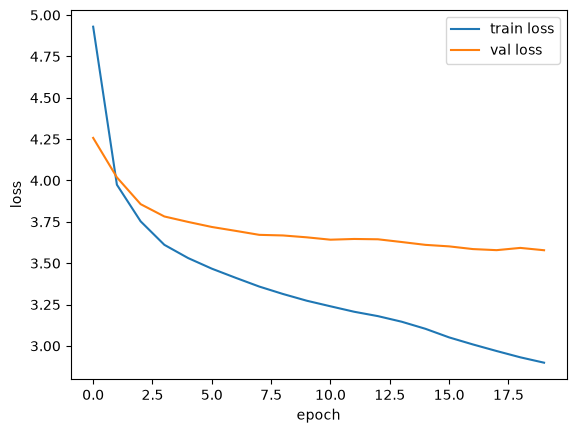

In [9]:
import matplotlib.pyplot as plt

# Compare training loss and validation loss over the epochs
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()